# Conversation History



## 1. Intro: LLMs are stateless

In this unit, we'll learn how to keep relevant information available across multiple LLM requests.

An LLM request is processed using the input supplied to that request. A separate request does not automatically include the previous request's text.

Imagine we send these as two separate API calls:

1. “I'm planning a 5-day trip to the North of Spain in June. I love hiking and local food, but I don't like crowded tourist attractions.”
2. “Can you recommend an itinerary for my trip?”

The second request contains no trip details, so the model may ask for them or make assumptions. To have a useful follow-up, we must provide the relevant history or use a supported conversation-chaining feature.

In [1]:
import os
import time
import pandas as pd
import matplotlib.pyplot as plt
from openai import OpenAI

MODEL = "gpt-6-luna"
client = OpenAI(api_key=os.environ["OPENAI_API_KEY"])

def send_request(input, **kwargs):
    """Send one Responses API request using the unit's shared model."""
    return client.responses.create(model=MODEL, input=input, **kwargs)

In [ ]:
request_1 = (
    "I'm planning a 5-day trip to the North of Spain in June. "
    "I love hiking and local food, but I don't like crowded tourist attractions."
    "Is that a good time of the year?"
)

response_1 = send_request(request_1)
print("Request 1:", response_1.output_text)


print("\n\n")
print("---")
print("\n\n")


# Now let's send a new request (notice that no earlier trip details are included).
request_2 = "Can you recommend an itinerary for my trip?"

response_2 = send_request(request_2)
print("Request 2:", response_2.output_text)

Request 1: Yes—**June is a very good time** for a five-day trip to northern Spain, especially if you want hiking and good food without peak-summer crowds.

- **Weather:** Days are long and usually pleasantly mild, but the north is greener—and more changeable—than much of Spain. Bring a light waterproof layer and check the forecast daily.
- **Hiking:** Coastal walks and lower-elevation trails are generally a great bet. In the **Picos de Europa**, higher routes can still have snow or difficult conditions, particularly in early June, so check local trail and mountain reports.
- **Crowds:** June is usually quieter than July and August, though weekends and popular spots can still get busy. **San Juan celebrations around 23 June** can bring extra visitors to some coastal towns.
- **Food:** It’s an excellent season to explore local markets, seafood, cider houses and regional dishes.

For a less hectic trip, choose a base outside the best-known resort towns and hike early in the day. Asturias,

## 2. Who manages the state?

There are two common approaches:

- **Client-managed:** your application stores the messages and sends the relevant history with each request.
- **OpenAI-managed chaining:** your application stores a response ID and supplies it as `previous_response_id` for the next request.

Both approaches still require you to think about what context is sent and how much it costs.

### 2.1 Client-managed state

A conversation history is a list of messages. Each message has a role and content.

| Role | Purpose |
|---|---|
| `system` / `developer` | Instructions about the assistant's behavior. The Responses API supports `instructions` as another way to provide system/developer-level instructions. |
| `user` | What the person asks or tells the assistant. |
| `assistant` | The model's previous replies, included so it can continue coherently. |

For a simple text conversation, append the user's message, send the full list, and append the assistant's reply.

In [17]:
SYSTEM_PROMPT = (
    "You are a practical travel planner. Respect the user's preferences "
    "and clearly state when you are unsure."
)

history = [{"role": "system", "content": SYSTEM_PROMPT}]

def chat(user_text):
    history.append({"role": "user", "content": user_text})
    response = send_request(history)
    answer = response.output_text
    history.append({"role": "assistant", "content": answer})
    return answer

print(chat(request_1))

print("\n\n ... \n\n")

print(chat(request_2))

Yes—**June is generally an excellent time** for northern Spain if you enjoy hiking and food. It’s usually green, the days are long, and temperatures are often comfortable for walking. It’s also typically less busy than July and August.

A few things to keep in mind:

- **Early June is usually quieter.** Crowds start to build toward the end of the month, especially around popular coast and mountain spots. The night of **June 23–24 (San Juan)** can be busy in coastal towns.
- **Expect changeable weather.** Rain, mist, and cool evenings are possible even in June, so bring waterproof layers and check the forecast.
- **High mountain routes may still have snow or difficult conditions**, particularly early in the month. Check local trail conditions before setting out.
- For a quieter hike, look beyond the most famous stops—for example, **Somiedo or Redes Natural Parks in Asturias**. The Picos de Europa are spectacular, but some access points and trails can be busy.

For a five-day trip, I’d f

In [ ]:
# Let's see the complete client-managed history, including the system message:
for message in history:
    print(message)

{'role': 'system', 'content': "You are a practical travel planner. Respect the user's preferences and clearly state when you are unsure."}
{'role': 'user', 'content': "I'm planning a 5-day trip to the North of Spain in June. I love hiking and local food, but I don't like crowded tourist attractions.Is that a good time of the year?"}
{'role': 'assistant', 'content': 'Yes—**June is generally an excellent time** for a 5-day trip to northern Spain, especially if you want hiking and good food without peak-summer crowds.\n\n- **Weather:** Days are usually mild and green, but the Atlantic coast can be changeable. Expect occasional rain and cooler evenings, so bring layers and a waterproof jacket.\n- **Hiking:** Coastal walks and lower-elevation trails are usually a good bet. In the **Picos de Europa** and other high mountains, some routes may still have snow or difficult conditions in early June; check local trail reports before setting out.\n- **Crowds:** June is typically quieter than July 

### 2.2 OpenAI-managed state with `previous_response_id`

Instead of managing and resending the entire conversation history ourselves, we can use OpenAI's previous_response_id parameter to link a new response to a previous one. This allows us to maintain conversational continuity across multiple API calls without manually passing the full message history each time.

Let's see that in action!

In [5]:
first = send_request(
    request_1,
    instructions=SYSTEM_PROMPT,
)

second = send_request(
    request_2,
    previous_response_id=first.id,
    instructions=SYSTEM_PROMPT,  # Repeat instructions on every request.
)

print(second.output_text)

For **hiking, local food and fewer crowds**, I’d focus on **Asturias rather than trying to cover the whole north**. This relaxed five-day route combines the quieter mountains of Somiedo with the western Asturian coast.

**Assumption:** you’ll rent a car and fly in and out of Asturias Airport. Stay **two nights around Pola de Somiedo or Valle de Lago**, then **two nights near Luarca or Valdés**.

### Day 1 — Arrive and head to Somiedo
Drive to your mountain base (roughly 1¾–2 hours from the airport). Settle in, take a short walk, and have a local dinner—look for **fabada**, **pote asturiano** or local cheeses.

### Day 2 — Hike in Somiedo Natural Park
Choose a walk to suit your energy:
- **Braña de Mumián:** a shorter, quieter-feeling walk to traditional stone-and-thatch shepherds’ huts.
- **Valle de Lago:** a longer walk to the glacial lake, with broad mountain scenery.

Start early for a quieter trail and bring waterproof layers; mountain weather can change quickly. In June, check loc


**Important:** the `instructions` parameter is not automatically carried forward when using `previous_response_id`. If you want the same instructions to apply on every request, provide them again each time.


### 2.3 Comparison

| | Client-managed history | OpenAI-managed chaining |
|---|---|---|
| Simplicity | More code to append and manage messages | Simple follow-up using a response ID |
| Control | Full control over what is included or removed | Less direct control over the chained context |
| Cost | Re-sent history counts as input | Prior context in the chain is still billed as input; chaining is not a way to make history free |
| Trimming and editing | Straightforward: edit the message list | Requires planning how to start or continue a chain |
| App responsibilities | Store and manage the messages | Store response IDs and manage the conversation flow |

**Rule of thumb:** use client-managed history when you need to inspect, trim, or summarize context yourself. Chaining is convenient when you want straightforward follow-ups without manually resending the list.

## 3. Context window, tokens, and cost

A **context window** is the amount of information a model can process for a request, including input and generated output. Text is measured in **tokens**—small pieces of text—not directly in words. You don't need to count tokens yourself to start: the API returns usage statistics on each response in `response.usage`.

With client-managed history, each turn usually sends the system prompt and previous messages again. As the conversation grows, later requests contain more input. The total input processed across a long conversation can therefore grow roughly quadratically when each turn adds a similar amount of text.

In [7]:
response = send_request(
    [{"role": "user", "content": "Suggest one hiking-friendly destination in northern Spain."}]
)

print("Input tokens:", response.usage.input_tokens)
print("Output tokens:", response.usage.output_tokens)
print("Total tokens:", response.usage.total_tokens)

Input tokens: 15
Output tokens: 128
Total tokens: 143


### Measure tokens in a longer conversation

The following demo makes multiple API calls and records input tokens, output tokens, and elapsed time. Each request includes the full client-managed history. To keep the demonstration focused, the assistant is asked to be concise.



In [ ]:
demo_history = [{"role": "system", "content": SYSTEM_PROMPT}]
metrics = []
turn_prompts = [
    "Let's plan a five-day trip to northern Spain in June.",
    "I love hiking. Suggest a suitable region.",
    "I also enjoy local food. Give one food idea.",
    "I don't like crowded tourist attractions. Suggest a quieter activity.",
    "What should I pack for the weather?",
    "Suggest a relaxed plan for day two.",
    "Give me one local dish to try.",
    "Briefly recap the preferences I've shared.",
]

for turn, prompt in enumerate(turn_prompts, start=1):
    demo_history.append({"role": "user", "content": prompt})
    start = time.perf_counter()
    response = send_request(
        demo_history,
        instructions="Be concise. Keep track of the trip preferences stated in the conversation.",
        max_output_tokens=180,
    )
    elapsed = time.perf_counter() - start
    answer = response.output_text
    demo_history.append({"role": "assistant", "content": answer})
    metrics.append({
        "turn": turn,
        "input_tokens": response.usage.input_tokens,
        "output_tokens": response.usage.output_tokens,
        "seconds": elapsed,
    })

df = pd.DataFrame(metrics)
df

,turn,input_tokens,output_tokens,seconds
0,1,59,180,4.208671
1,2,122,180,4.387823
2,3,143,180,3.887684
3,4,165,180,4.079607
4,5,183,180,4.787482
5,6,248,180,3.642160
6,7,266,129,3.295784
7,8,305,134,2.666285


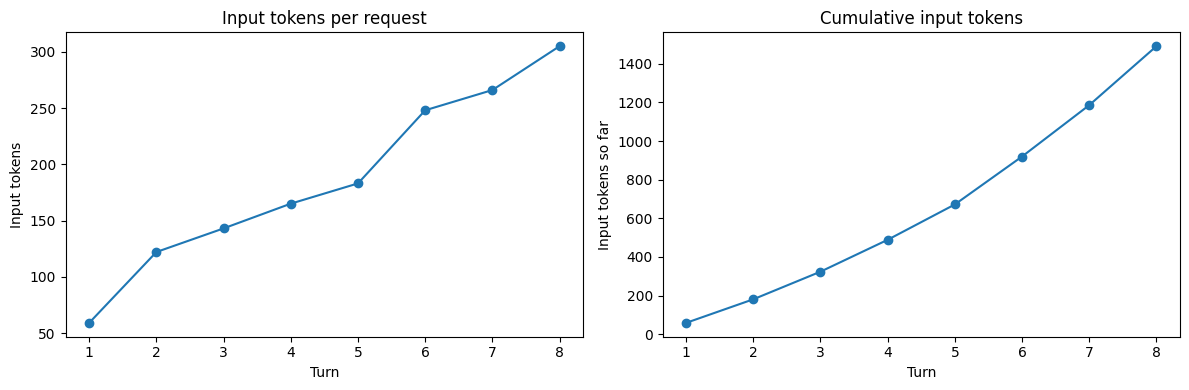

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot 1: Shows the number of input tokens used in each individual request.
axes[0].plot(df["turn"], df["input_tokens"], marker="o")
axes[0].set_title("Input tokens per request")
axes[0].set_xlabel("Turn")
axes[0].set_ylabel("Input tokens")

# Plot 2: Shows the total input tokens accumulated across all requests up to each turn.
axes[1].plot(df["turn"], df["input_tokens"].cumsum(), marker="o")
axes[1].set_title("Cumulative input tokens")
axes[1].set_xlabel("Turn")
axes[1].set_ylabel("Input tokens so far")

plt.tight_layout()
plt.show()

As you can see, later requests tend to use more input tokens because they include more history.
This can have important implications in cost and latency.


## 4. Strategies to Manage Long Conversations

As history grows, we must decide what to keep. Every strategy trades off completeness (what the model can remember) against cost, latency, and the risk of hitting the context limit. We will reuse the same trip-planning scenario and the `chat()` history format. The aim is not to keep everything, but to keep the information needed for the next answer.

### Strategy 1: Sliding window (truncation)

Keep the system message and only the most recent messages; drop older messages. The helper below treats `max_messages` as the maximum number of **non-system** messages to retain and removes whole user/assistant pairs where possible, so it does not leave a dangling half-pair.

In [11]:
def trim_history(history, max_messages=6):
    system_messages = [m for m in history if m["role"] == "system"]
    messages = [m for m in history if m["role"] != "system"]
    messages = messages[-max_messages:]

    # If trimming starts with an assistant reply, drop it to preserve pair order.
    while messages and messages[0]["role"] == "assistant":
        messages.pop(0)

    return system_messages[:1] + messages

#### Demo: an early detail is dropped

Use the trip-planning conversation, then trim it to the most recent messages. Ask about a preference stated in the first message. Depending on the retained window, the model may not know the answer and may guess. This is the main drawback of truncation: early details can disappear.

In [12]:
trip_history = [{"role": "system", "content": SYSTEM_PROMPT}]
trip_history.append({"role": "user", "content": request_1})
trip_response = send_request(trip_history)
trip_history.append({"role": "assistant", "content": trip_response.output_text})

# Add enough later conversation to push the first user message out of the window.
for prompt in [
    "Suggest a hiking area for this trip.",
    "Recommend a local dish.",
    "What could I do on day two?",
    "Suggest a quiet evening activity.",
    "What should I pack?",
    "Give me a short itinerary recap.",
]:
    trip_history.append({"role": "user", "content": prompt})
    response = send_request(trip_history)
    trip_history.append({"role": "assistant", "content": response.output_text})

trimmed_history = trim_history(trip_history, max_messages=6)
print("Messages retained:")
for message in trimmed_history:
    print(message["role"], ":", message["content"][:180])

Messages retained:
system : You are a practical travel planner. Respect the user's preferences and clearly state when you are unsure.
user : Suggest a quiet evening activity.
assistant : After dinner, take a **slow stroll around Pola de Somiedo** and enjoy the mountain views as the light fades. If the sky is clear, step somewhere dark near your accommodation for a 
user : What should I pack?
assistant : For a **five-day June trip based in Somiedo**, pack for changeable mountain weather—sunny and warm one moment, cool or rainy the next.

**For hikes**
- Broken-in hiking shoes or bo
user : Give me a short itinerary recap.
assistant : ### Five days in Somiedo — a relaxed draft
- **Day 1:** Arrive and settle in around Pola de Somiedo or Valle de Lago; have a quiet evening and try local Asturian food.
- **Day 2:**


In [ ]:
# Worth mentioning: if you use a sliding window, it can help to add a note in the system prompt so that the model doesn't make assumptions.

forgotten_detail_question = "What did I say I didn't like?"
trimmed_history.append({"role": "user", "content": forgotten_detail_question})
trimmed_response = send_request(
    trimmed_history,
    instructions="If the answer is not present in the available conversation, say you don't know rather than guessing.",
)
print(trimmed_response.output_text)

You haven’t mentioned anything you dislike yet.


**Pros / cons:** Sliding windows are simple, cheap, and predictable. But they can discard important early information, so the model may no longer know a user's original preferences.

### Strategy 2: Summarization

When history exceeds a threshold, ask the model to summarize older messages, replace those messages with a summary, and keep the latest few messages verbatim. A good summary prompt explicitly asks to preserve user preferences, constraints, and decisions.

In [14]:
def summarize_history(history):
    system_messages = [m for m in history if m["role"] == "system"]
    messages = [m for m in history if m["role"] != "system"]

    # Keep the most recent four messages verbatim; summarize older messages.
    older = messages[:-4]
    recent = messages[-4:]
    if not older:
        return history

    summary_input = [
        {
            "role": "developer",
            "content": (
                "Summarize this conversation for future turns. Preserve the user's "
                "preferences, constraints, decisions, and important facts. Do not "
                "invent details. Be concise."
            ),
        },
        {
            "role": "user",
            "content": "\n\n".join(
                f'{m["role"].upper()}: {m["content"]}' for m in older
            ),
        },
    ]
    summary_response = send_request(summary_input, max_output_tokens=250)
    summary_message = {
        "role": "assistant",
        "content": "Conversation summary (may omit details): " + summary_response.output_text,
    }
    return system_messages[:1] + [summary_message] + recent

#### Demo: preserve the trip preference

Summarize the older part of the same trip conversation and retain the latest messages. Then ask the same question. Print the compressed history and compare the input-token count for the question before and after compression. The token counts are measured from actual API responses.

In [15]:
summarized_history = summarize_history(trip_history)

print("Compressed history:")
for message in summarized_history:
    print(f'[{message["role"]}] {message["content"][:300]}')

Compressed history:
[system] You are a practical travel planner. Respect the user's preferences and clearly state when you are unsure.
[assistant] Conversation summary (may omit details): The user is planning a **5-day trip to northern Spain in June**. They enjoy **hiking and local food** and prefer to avoid crowded tourist attractions.

- June is generally a good time, though Atlantic weather can be changeable; pack rain gear and check mounta
[user] What should I pack?
[assistant] For a **five-day June trip based in Somiedo**, pack for changeable mountain weather—sunny and warm one moment, cool or rainy the next.

**For hikes**
- Broken-in hiking shoes or boots with good grip  
- Waterproof rain jacket; lightweight waterproof trousers are useful  
- Quick-drying hiking trouse
[user] Give me a short itinerary recap.
[assistant] ### Five days in Somiedo — a relaxed draft
- **Day 1:** Arrive and settle in around Pola de Somiedo or Valle de Lago; have a quiet evening and try local Asturia

In [16]:
question = "What did I say I didn't like?"

before_response = send_request(
    trip_history + [{"role": "user", "content": question}],
    instructions="If the answer is not present in the available conversation, say you don't know rather than guessing.",
)
after_response = send_request(
    summarized_history + [{"role": "user", "content": question}],
    instructions="If the answer is not present in the available conversation, say you don't know rather than guessing.",
)

print("Before compression — input tokens:", before_response.usage.input_tokens)
print("After compression  — input tokens:", after_response.usage.input_tokens)
print("\nAnswer with summary:", after_response.output_text)

Before compression — input tokens: 1283
After compression  — input tokens: 663

Answer with summary: You said you prefer to avoid crowded tourist attractions.


**Pros / cons:** Summarization can preserve key information while keeping context bounded. It requires an extra LLM call, adds latency, and may omit details or introduce errors.

### Compare the strategies

| | Sliding window | Summarization |
|---|---|---|
| Complexity | Low | Medium |
| Cost | Low; no summary call | Extra call when summarizing |
| Memory quality | Keeps only recent verbatim messages | Can preserve important early facts |
| Main risk | Old details disappear | Summary omits or distorts details |

**Rule of thumb:** use a sliding window for casual chats where old context is unlikely to matter; use summarization when early details matter. In production, a common approach is to combine a compact summary with a recent-message window.

### Other approaches

- **Persist important facts outside the conversation:** an application might save a preference and add it to the instructions on a later request. This is a separate design choice and is not implemented in this unit.
- **Retrieval-based memory:** store past messages and retrieve only those relevant to the current question. We will cover retrieval concepts in a later unit on RAG.

### Key takeaways

- As history grows, input-token cost and often latency grow too.
- You must decide what information to keep in the context.
- Trimming is simple and predictable, but it can lose important details.
- Summarization preserves meaning more compactly, at the price of an extra call and possible information loss.

## 5. Challenges and limitations

Even with good history management, long conversations have inherent limits. In production, watch for context limits, missed details, memory errors, rising cost, and privacy obligations.

Context window limits:
- Every model has a maximum context size. If input plus output exceeds it, the API may return an error or apply truncation depending on the request settings. A larger context window delays the problem, but does not remove it—and processing more context can increase cost and latency.

“Lost in the middle” / context rot:
- Models may not use every part of a long context equally well. Details buried in the middle can be missed more easily, and answer quality can degrade as context grows even when it still fits.
- **Practical implication:** more context is not always better. Keep history relevant, put critical instructions at the start, and restate essential details near the end when appropriate.

Information loss and drift:
- Trimming drops messages, and summaries can omit or distort facts. Repeatedly summarizing an earlier summary can compound errors. Over many turns, a model may also drift from the original instructions or persona.

Hallucinated memory:
- When a detail is missing, a model may invent a plausible answer instead of admitting it does not know. The sliding-window demo illustrates this risk. Mitigate it by explicitly instructing the model to say when the available context does not contain the answer.

Cost and latency at scale:
- Costs multiply across users and turns. Common mitigations include prompt caching, using a cheaper model for summarization, capping conversation length, and tracking `usage` per conversation.

Privacy and data retention:
- Conversation history may contain personal or sensitive information. With client-managed state, your application controls how messages are stored and deleted. With OpenAI-managed chaining, response data is stored on OpenAI's servers; retention depends on the applicable settings and policies, so check the current [OpenAI data controls documentation](https://platform.openai.com/docs/guides/your-data). Store only what is needed, redact sensitive data where possible, and be clear with users about what is remembered.

### Summary table

| Challenge | Why it happens | Mitigation |
|---|---|---|
| Context window limit | Input and output exceed the model's maximum | Trim or summarize; handle limit errors |
| Lost in the middle / context rot | Long context can make details harder to use | Keep context relevant; restate critical facts |
| Information loss and drift | Trimming and summaries lose or alter details | Preserve key facts; review summary quality |
| Hallucinated memory | Missing facts invite plausible guesses | Instruct the model to say when it doesn't know |
| Cost and latency at scale | Many users and turns multiply token usage | Cache stable prompts, use cheaper summaries, cap length, track usage |
| Privacy and retention | History can contain sensitive data and may be retained | Minimize and redact data; explain retention and memory behavior |

### Wrap-up

- There is no perfect memory solution.
- The goal is to keep the **right** information in context, not **all** of it.
- Monitor token usage and test long conversations explicitly.

## 6. Conclusions

- LLM requests need relevant conversation context to answer follow-up questions reliably.
- You can manage the message history yourself or chain responses with `previous_response_id`.
- Longer histories increase input-token usage and often latency.
- Sliding windows are simple but lossy; summarization can retain key details but adds cost and can introduce errors.
- Production systems should monitor context, cost, answer quality, and data retention.